# `da6idb` — reading APS 6-ID-B data in a notebook

Everything the viewers in this repository do, without a window: the master
files, the detector stack, reciprocal space, and the slices and cuts taken
through it.

It runs against the scans that travel with the repository. `tise2_2_00152` is
a 101-point `psic_eta` rocking curve with its detector stack, and `00155` and
`00158` are the same measurement repeated, which the last section uses to show
several scans put on one lattice. Point `FOLDER` somewhere else and the rest
should follow.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# Installing the package (pip install -e . from the repository root) makes
# this unnecessary, but the notebook should run either way.
REPO = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
try:
    import da6idb
except ModuleNotFoundError:
    sys.path.insert(0, str(REPO))
    import da6idb

FOLDER = REPO          # the repository root, which holds the example scans
SCAN = 152
print("da6idb", da6idb.__version__)

da6idb 0.1.0.dev0


## What is in the folder

`open_folder` finds every master file and pairs it with its detector file.
`summary()` is a DataFrame, so sort and filter it however you like.

In [2]:
folder = da6idb.open_folder(FOLDER)
print(folder.numbers)
folder.summary().head(12)

[6, 7, 8, 9, 10, 11, 34, 83, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 353, 354, 355]


,plan,motors,range,points,count_time,image,file
scan,,,,,,,
6,scan,"rp100_output1_voltage_pv, rp100_output2_voltag...",rp100_output1_voltage_pv 0→100 (101); rp100_ou...,101,1.0,True,tise2_2_00006_master.hdf
7,rel_scan,psic_eta,psic_eta 19.6295→23.6296 (101),101,1.0,True,tise2_2_00007_master.hdf
8,rel_scan,psic_eta,psic_eta 31.7869→35.787 (101),101,1.0,True,tise2_2_00008_master.hdf
9,scan,"rp100_output1_voltage_pv, rp100_output2_voltag...",rp100_output1_voltage_pv 100→0 (101); rp100_ou...,101,1.0,True,tise2_2_00009_master.hdf
10,rel_scan,psic_eta,psic_eta 31.8999→35.9 (101),101,1.0,True,tise2_2_00010_master.hdf
11,scan,"rp100_output1_voltage_pv, rp100_output2_voltag...",rp100_output1_voltage_pv 0→-50 (101); rp100_ou...,101,1.0,True,tise2_2_00011_master.hdf
34,grid_scan,"psic_eta, psic_chi",psic_eta 9.9→10.1 (25); psic_chi 89.9→90.1 (25),25,1.0,True,lineup_00034_master.hdf
83,scan,"rp100_output1_voltage_pv, rp100_output2_voltag...",rp100_output1_voltage_pv 50→-50 (101); rp100_o...,101,1.0,True,tise2_2_00083_master.hdf
151,rel_scan,cryo_z,cryo_z -1.49989→-1.09987 (41),41,1.0,True,tise2_2_00151_master.hdf


## One scan

Indexing by scan number gives a `Scan`. Everything else hangs off it.

In [3]:
scan = folder[SCAN]
print(scan.plan, "|", scan.motors, "|", scan.points, "points")
scan

rel_scan | ['psic_eta'] | 101 points


<Scan 00152 'rel_scan' psic_eta — 101 points>

### Which field is which

The first question in front of an unfamiliar scan is what to plot. `fields`
lists every name in the stream and says what it is: the motor the scan moved
sorts first, the detector the plan nominated is marked `hinted`, and the
fields that never moved sort last. A channel that barely varies around a
large positive value — an ion chamber — is your monitor.

Nothing here is guessed from the name. `role` comes from the plan's own
`motors` list, from the `signal_type` each field carries, and from the PV it
was read from.

In [4]:
scan.fields()

,role,hinted,units,varies,min,max,source
field,,,,,,,
psic_eta,scanned,False,degrees,True,2.069174e+01,2.269179e+01,PV:6idb1:m17.RBV
lambda250k_stats3_total,detector,True,,True,2.494060e+05,3.134790e+05,PV:s6lambda1:Stats3:Total_RBV
EPOCH,time,False,,True,1.790516e+09,1.790516e+09,
INDEX,index,False,,True,0.000000e+00,1.000000e+02,
Ion Chamber 4,detector,False,,True,1.338390e+05,1.342080e+05,PV:6idb1:scaler1.S5
Sawtooth_Bottom,detector,False,,True,1.442997e+06,1.443032e+06,PV:6idb1:scaler1.S6
ah2700a_capacitance,detector,False,,True,8.892000e-01,8.896600e-01,PV:6idb1:AH2700A:1:CAP
ah2700a_loss,detector,False,,True,0.000000e+00,1.800000e-03,PV:6idb1:AH2700A:1:LOSS
lambda250k_stats1_total,detector,False,,True,1.450500e+04,4.153100e+04,PV:s6lambda1:Stats1:Total_RBV


In [5]:
# just the ones worth an axis
table = scan.fields()
table[table["varies"] == True]

,role,hinted,units,varies,min,max,source
field,,,,,,,
psic_eta,scanned,False,degrees,True,2.069174e+01,2.269179e+01,PV:6idb1:m17.RBV
lambda250k_stats3_total,detector,True,,True,2.494060e+05,3.134790e+05,PV:s6lambda1:Stats3:Total_RBV
EPOCH,time,False,,True,1.790516e+09,1.790516e+09,
INDEX,index,False,,True,0.000000e+00,1.000000e+02,
Ion Chamber 4,detector,False,,True,1.338390e+05,1.342080e+05,PV:6idb1:scaler1.S5
Sawtooth_Bottom,detector,False,,True,1.442997e+06,1.443032e+06,PV:6idb1:scaler1.S6
ah2700a_capacitance,detector,False,,True,8.892000e-01,8.896600e-01,PV:6idb1:AH2700A:1:CAP
ah2700a_loss,detector,False,,True,0.000000e+00,1.800000e-03,PV:6idb1:AH2700A:1:LOSS
lambda250k_stats1_total,detector,False,,True,1.450500e+04,4.153100e+04,PV:s6lambda1:Stats1:Total_RBV


## Curves

`curve` takes an x field and any number of y fields, and normalises if asked.
Left to itself it uses the motor the scan moved — or the point index, for a
plan that moved nothing.

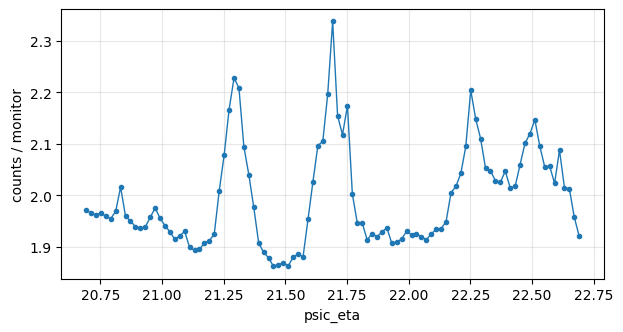

In [6]:
curve = scan.curve(y="lambda250k_stats3_total", normalise="Ion Chamber 4")
ax = curve.plot(marker="o", ms=3, lw=1, figsize=(7, 3.5), legend=False)
ax.set_ylabel("counts / monitor"); ax.grid(alpha=0.3)

In [7]:
scan.statistics("lambda250k_stats3_total")   # max, min, half-max centre and FWHM

,max_y,max_x,min_y,min_x,center,fwhm
lambda250k_stats3_total,313479.0,21.691766,249406.0,21.451815,21.697083,0.126549


In [8]:
scan.hkl_position()        # where the diffractometer sat, averaged over the scan

,mean,spread
axis,,
H,1.013464,0.002557
K,-0.492560,0.038620
L,7.484036,0.001328


A two-motor raster comes back as a labelled 2D array instead:

('psic_eta', 'psic_chi') (5, 5)


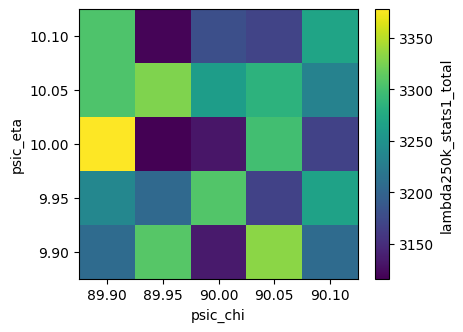

In [9]:
raster = folder[34].map("lambda250k_stats1_total")
print(raster.dims, raster.shape)
raster.plot(figsize=(4.5, 3.5))

## The detector frames

`images()` finds the detector file the way the viewers do, and brings the ROIs
the beamline recorded — from the image file, or from the master's baseline
when the image has none.

In [10]:
images = scan.images()
print(images)
images.rois

<Images pva_tise2_2_00152.h5 — 101 x 516x516>


,name,x,y,w,h,angle
0,ROI1,286.0,335.0,50.0,5.0,0.0
1,ROI2,286.0,330.0,50.0,15.0,0.0
2,ROI3,111.0,333.0,400.0,10.0,0.0
3,ROI4,111.0,328.0,400.0,20.0,0.0


### Setting your own ROI

`show` draws a frame the way the image viewer does — x across, y down,
labelled in detector pixels — with the recorded ROIs on it. Read a rectangle
off those axes and hand it back as `(x, y, w, h)`: everywhere an ROI index is
taken, a rectangle is taken too.

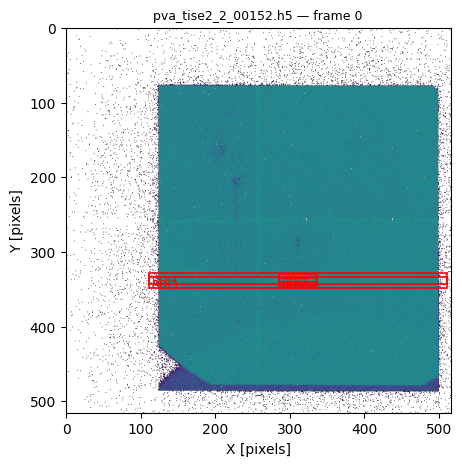

In [11]:
images.show(0, log=True);        # rois=() for a bare frame

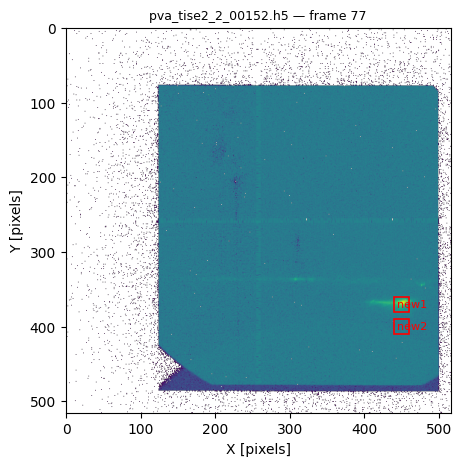

In [12]:
# the recorded ROIs are strips across y = 328-343 and miss the spot near
# x = 440, y = 360, so put a box of our own on it and an empty one below
spot = (440, 360, 20, 20)                      # x, y, width, height
bg   = (440, 390, 20, 20)
peak = int(images.roi_curve(spot, "sum").idxmax())
images.show(peak, rois=[spot, bg], log=True);

`roi_series` reduces every frame to all six metrics; `roi_curve` picks one out.
`background` takes a rectangle just as `roi` does — its mean per pixel comes
off, which matters whenever the box holds more background than feature.

In [13]:
images.roi_series(spot).head()

,sum,mean,min,max,comx,comy
frame,,,,,,
0,26365.0,65.9125,15.0,94.0,9.440698,9.538365
1,26746.0,66.8650,13.0,101.0,9.415838,9.531519
2,26805.0,67.0125,24.0,108.0,9.516396,9.444469
3,26686.0,66.7150,12.0,102.0,9.460316,9.487709
4,26328.0,65.8200,20.0,103.0,9.409032,9.491720


floor as a fraction of the peak: 4.9% raw, -0.4% corrected

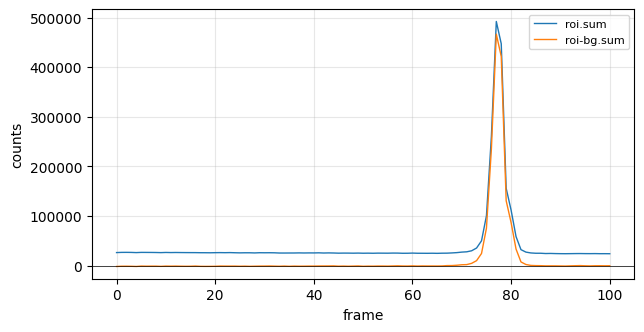

In [14]:
raw = images.roi_curve(spot, "sum")
corrected = images.roi_curve(spot, "sum", background=bg)
ax = raw.plot(figsize=(7, 3.5), lw=1, label=raw.name)
corrected.plot(ax=ax, lw=1, label=corrected.name)
ax.axhline(0, color="k", lw=0.5); ax.set_ylabel("counts")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
print(f"floor as a fraction of the peak: {raw.min() / raw.max():.1%} raw, "
      f"{corrected.min() / corrected.max():.1%} corrected")

### The scattering angle of what is in the ROI

The detector circle reads the angle of one pixel: the centre. A feature
anywhere else is at a different two theta, and on a 2D detector that offset is
not along one axis only. `two_theta_angles` asks xrayutilities where the ROI's
pixels actually point, through the same geometry the HKL conversion uses;
`two_theta` averages the scan into one number, weighted by intensity.

Subtract the background here too: left in, it drags the answer towards the
middle of the box rather than the feature.

detector circle reads 46.78862 deg  (the centre pixel)
spot, scan average    46.67796 deg


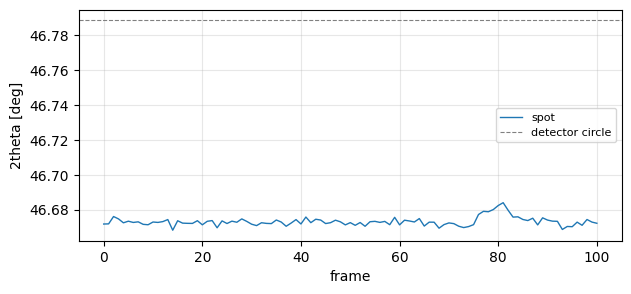

In [15]:
g = images.geometry()
print(f"detector circle reads {g.detector_angles[1][0]:.5f} deg  (the centre pixel)")
print(f"spot, scan average    {images.two_theta(spot, background=bg):.5f} deg")

tth = images.two_theta_angles(spot, background=bg)
ax = tth.plot(figsize=(7, 3), lw=1, label="spot")
ax.axhline(g.detector_angles[1][0], color="grey", ls="--", lw=0.8,
           label="detector circle")
ax.set_ylabel("2theta [deg]"); ax.legend(fontsize=8); ax.grid(alpha=0.3)

## Reciprocal space

`hkl()` gathers the geometry from the master, the image file and any
`hkl_setup.json` in the folder, and says where each piece came from. The
angles are the one thing taken from the image file first, since it records
them per frame rather than per scan point.

In [16]:
m = scan.hkl()
m.sources()

angles              image
center_pixel       master
detector_dirs       image
detector_size       image
distance           master
energy_kev         master
inplane             image
pixel_direction    master
primary_beam        image
sample_dirs         image
surface             image
transmission        image
ub                 master
Name: source, dtype: str

In [17]:
print(m.extent())          # the H, K, L box the scan reaches
m.resolution()             # and the cell size that sampling supports

        low      high
H  0.919476  1.159641
K -0.634439 -0.352504
L  7.337101  7.704919


volume_per_sample    3.011909e-10
frame_gap            1.235297e-03
in_plane             4.937504e-04
cell                 6.703176e-04
footprint_H          3.645253e-04
footprint_K          1.336434e-03
footprint_L          5.620182e-04
dtype: float64

### Gridding

`grid` bins the frames onto a regular lattice and caches it as the same `.vti`
the viewers read. `hkl_range` crops it — `(h_min, h_max, k_min, k_max, l_min,
l_max)` — and `step` sets the cell outright; each combination caches to its own
file, so asking again is a reload rather than a regrid.

In [18]:
BOX = (0.98, 1.10, -0.56, -0.42, 7.44, 7.60)
STEP = 0.0012

cube = m.grid(hkl_range=BOX, step=STEP)
print(cube.dims, cube.shape)
print(Path(cube.attrs["path"]).name)
cube

('H', 'K', 'L') (101, 118, 134)
pva_tise2_2_00152_hkl_0.98_1.1_-0.56_-0.42_7.44_7.6.vti


<xarray.DataArray 'intensity' (H: 101, K: 118, L: 134)> Size: 6MB
array([[[          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        ...,
        [8.6233322e+01, 7.2880196e+01, 7.9909126e+01, ...,
         6.4623062e+01, 6.6767693e+01, 6.7609596e+01],
        [7.5088707e+01, 8.1665810e+01, 7.7212189e+01, ...,
         6.1045040e+01, 6.2511738e+01, 6.0101337e+01],
        [8.3251427e+01, 8.5811615e+01, 7.3853172e+01, ...,
         6.2553223e+01, 7.4648094e+01, 6.3351845e+01]],

       [[          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
...
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan]],

       [[0.0000000e+00, 2.0492371e-02, 2.1876849e-02, ...,
         2.0612810e+00, 8.0123625e+00, 3.4336829e+00],
        [0.0000000e+00, 3.3057850e-02, 1.7044527e-02, ...,
         4.2417898e+00, 1.6242001e+01, 2.4175112e+01],
        [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ...,
         1.1100145e+01, 2.6473972e+01, 2.8970692e+01],
        ...,
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan]]],
      shape=(101, 118, 134), dtype=float32)
Coordinates:
  * H        (H) float64 808B 0.98 0.9812 0.9824 0.9836 ... 1.098 1.099 1.1
  * K        (K) float64 944B -0.56 -0.5588 -0.5576 ... -0.4224 -0.4212 -0.42
  * L        (L) float64 1kB 7.44 7.441 7.442 7.444 ... 7.596 7.598 7.599 7.6
Attributes:
    hkl_range:               [0.98, 1.1, -0.56, -0.42, 7.44, 7.6]
    step:                    [0.0011999999999999789, 0.0011965811965811701, 0...
    width:                   [0.0003645252675839039, 0.0013364335217694867, 0...
    source_image:            pva_tise2_2_00152.h5
    source_master:           tise2_2_00152_master.hdf
    frames:                  101
    frame_range:             [0, -1, 1]
    geometry:                f203f0cd17684188
    oversample:              1.0
    transmission_corrected:  0
    filled_cells:            [1412060, 1597012]
    path:                    /Users/jwkim/Library/CloudStorage/Box-Box/python...

### A slice

`slice` cuts the lattice `grid` last built. Place the plane either by `offset`
— how far along the normal from the centre — or by `point`, an H, K, L it must
pass through, which is usually what you actually know. Either way the result
records both.

`.plot()` is xarray's, so the colours are matplotlib's arguments: `cmap`,
`vmin`/`vmax`, `robust=True` for the 2nd–98th percentile, or
`norm=LogNorm(...)`. Cells the scan never reached are NaN, so they stay blank
and stay out of the scaling.

('K', 'H') (118, 102) | offset -0.0


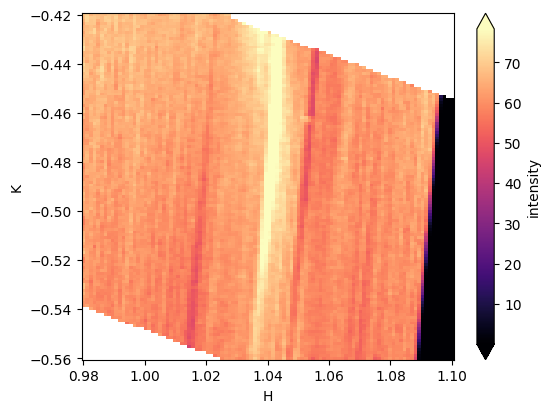

In [19]:
sl = m.slice(normal=(0, 0, 1), point=(1.04, -0.49, 7.52), layers=3)
print(sl.dims, sl.shape, "| offset", round(sl.attrs["offset"], 5))
sl.plot(figsize=(6, 4.5), cmap="magma", robust=True)

### A cut between two points

`cut` takes the two H, K, L the line runs between, so it can be written down
and repeated rather than aimed at by hand. `width` averages that many parallel
lines; give it the slice's `normal` and the widening stays in that plane.

,distance,H,K,L,intensity
0,0.000000,0.990000,-0.49,7.52,62.209033
1,0.001190,0.991190,-0.49,7.52,61.119373
2,0.002381,0.992381,-0.49,7.52,61.456165
3,0.003571,0.993571,-0.49,7.52,62.786609
4,0.004762,0.994762,-0.49,7.52,64.034363


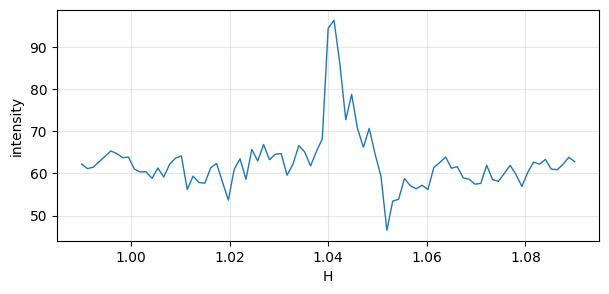

In [20]:
cut = m.cut((0.99, -0.49, 7.52), (1.09, -0.49, 7.52), width=5, normal=(0, 0, 1))
ax = cut.plot(x="H", y="intensity", figsize=(7, 3), lw=1, legend=False)
ax.set_ylabel("intensity"); ax.grid(alpha=0.3)
cut.head()

## Several scans on one lattice

To compare scans you need them on the *same* grid. Left to itself each scan
picks the cell its own sampling supports, and those differ — so the arrays
come out different shapes and cannot be stacked or subtracted.

Give every scan the same `hkl_range` **and** the same `step` and the lattices
match exactly. Then the same `slice` and the same `cut` mean the same thing in
every one of them.

In [21]:
SCANS = (152, 155, 158)        # the same rocking curve, measured three times

for n in SCANS:                # what each would choose on its own
    print(f"scan {n}: natural cell {folder[n].hkl().resolution()['cell']:.3e}")

scan 152: natural cell 6.703e-04
scan 155: natural cell 6.703e-04
scan 158: natural cell 6.703e-04


In [22]:
maps = {}
for n in SCANS:
    hkl = folder[n].hkl()
    hkl.grid(hkl_range=BOX, step=STEP)     # one box, one cell, every scan
    maps[n] = hkl
print({n: hkl.grid(hkl_range=BOX, step=STEP).shape for n, hkl in maps.items()})

{152: (101, 118, 134), 155: (101, 118, 134), 158: (101, 118, 134)}


### The same slice from each

Identical coordinates, so `xr.concat` stacks them into one cube with a `scan`
axis — and from there it is one line to facet them, difference them, or average
them.

('scan', 'K', 'H') (3, 118, 102)


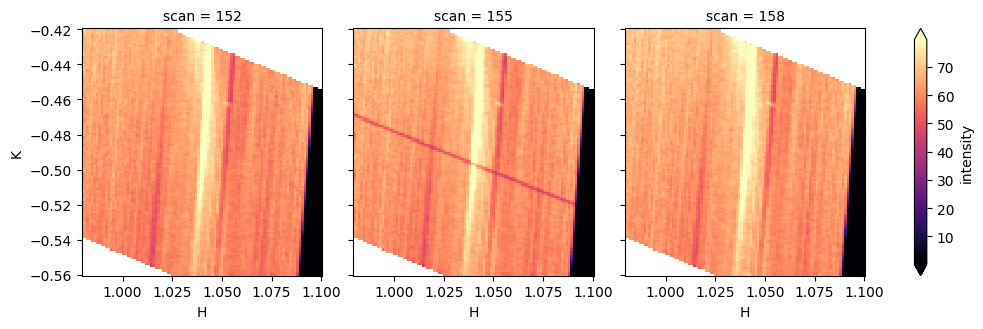

In [23]:
PLANE = dict(normal=(0, 0, 1), point=(1.04, -0.49, 7.52), layers=3)
slices = xr.concat([maps[n].slice(**PLANE) for n in SCANS],
                   dim=pd.Index(SCANS, name="scan"))
print(slices.dims, slices.shape)
slices.plot(col="scan", cmap="magma", robust=True, figsize=(11, 3.4))

Text(0.5, 1.0, 'scan 158 - scan 152')

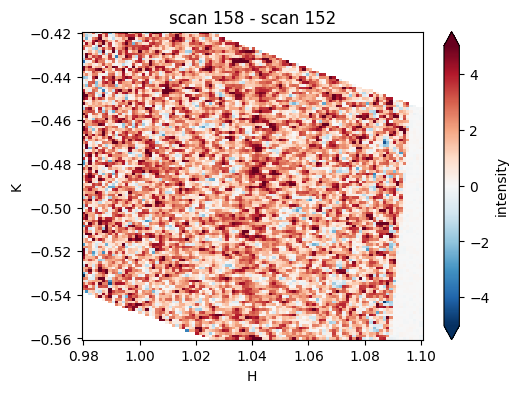

In [24]:
# what changed between the first and the last
change = slices.sel(scan=SCANS[-1]) - slices.sel(scan=SCANS[0])
change.plot(figsize=(5.5, 4), cmap="RdBu_r", robust=True)
plt.title(f"scan {SCANS[-1]} - scan {SCANS[0]}")

### The same cut from each

A cut is a table, so the tidy way is one frame with a `scan` column: group it,
plot it, fit it, write it out.

In [25]:
ENDS = ((0.99, -0.49, 7.52), (1.09, -0.49, 7.52))
cuts = []
for n in SCANS:
    one = maps[n].cut(*ENDS, width=5, normal=(0, 0, 1))
    one.insert(0, "scan", n)
    cuts.append(one)
cuts = pd.concat(cuts, ignore_index=True)
print(cuts.shape)
cuts.head()

(255, 6)


,scan,distance,H,K,L,intensity
0,152,0.000000,0.990000,-0.49,7.52,62.209033
1,152,0.001190,0.991190,-0.49,7.52,61.119373
2,152,0.002381,0.992381,-0.49,7.52,61.456165
3,152,0.003571,0.993571,-0.49,7.52,62.786609
4,152,0.004762,0.994762,-0.49,7.52,64.034363


,max,mean,H at peak
scan,,,
152,96.302051,62.627035,1.04119
155,97.065820,63.159228,1.04119
158,98.576111,64.616030,1.04000


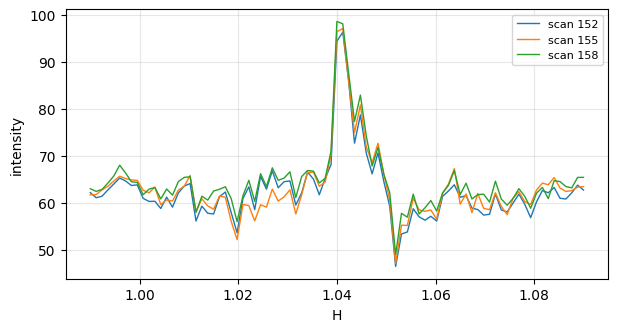

In [26]:
ax = None
for n, group in cuts.groupby("scan"):
    ax = group.plot(x="H", y="intensity", ax=ax, lw=1, label=f"scan {n}",
                    figsize=(7, 3.5))
ax.set_ylabel("intensity"); ax.grid(alpha=0.3); ax.legend(fontsize=8)

summary = cuts.groupby("scan")["intensity"].agg(["max", "mean"])
summary["H at peak"] = cuts.loc[cuts.groupby("scan")["intensity"].idxmax()] \
                           .set_index("scan")["H"]
summary

### Doing it in bulk

For a long run of scans, `batch.grid_scans` does the same loop and writes the
`.vti` files out, taking the cell size from the first scan that reads so the
rest match it. It returns one row per scan, with a note for any that failed.

The same thing from a terminal is `da6idb-grid`, and the batch window is
`python batch_grid.py`.

In [27]:
from da6idb import batch

results = batch.grid_scans(FOLDER, SCANS, hkl_range=BOX, step=STEP,
                           output=FOLDER / "output")
pd.DataFrame(results, columns=["scan", "path", "note"]).assign(
    path=lambda d: d["path"].map(lambda p: Path(p).name if p else None))

,scan,path,note
0,152,pva_tise2_2_00152_hkl_grid.vti,reused
1,155,pva_tise2_2_00155_hkl_grid.vti,reused
2,158,pva_tise2_2_00158_hkl_grid.vti,reused


## Writing it out

`export` writes the same formats the viewers do — the suffix chooses between
text, CSV, `.npz` and HDF5 — and carries a header saying where the numbers came
from. For anything else, these are ordinary pandas and xarray objects.

In [28]:
from da6idb import export

out = Path.cwd() / "exported"
out.mkdir(exist_ok=True)

export.write_dataarray(sl, out / "slice.txt", description=[f"scan {SCAN}"])
cuts.to_csv(out / "cuts.csv", index=False)
slices.to_netcdf(out / "slices.nc")

for item in sorted(out.iterdir()):
    print(f"{item.name:14} {item.stat().st_size / 1024:8.1f} kB")
print()
print(open(out / "slice.txt").read().split("\n")[0:6])

cuts.csv           17.7 kB
slice.txt          88.8 kB
slices.nc         284.3 kB

['# scan 152', '# offset: -3.019806626980426e-14', '# layers: 3', '# x axis: H  from 0.980000 to 1.100000  (102 points, step 0.00118812)', '# y axis: K  from -0.560000 to -0.420000  (118 points, step 0.00119658)', '# rows run along y, columns along x; unmeasured cells are nan']


## Where to look next

`docs/api.md` lists every public function, generated from the source. The
reading layers (`da6idb.files`, `da6idb.scan`, `da6idb.images`) need only
numpy, h5py and scipy; `da6idb.session` — everything used above — adds pandas
and xarray; `da6idb.hkl` adds xrayutilities and pyvista. None of it needs Qt.